# 04 - Leakage Analysis

## Objective

We suspect that `newbalanceOrig` and `newbalanceDest` are leaky. They describe the account *after* the transaction, and they seem tied to how PaySim creates fraud. Here we measure this with a model.

We train the same simple model twice, on the same split:

1. **Naive model**: with `newbalanceOrig`, `newbalanceDest` and the balance flags built from them.
2. **Leakage-aware model**: only features known *before* the transaction (`type`, `amount`, `oldbalanceOrg` and the amount-to-balance ratio).

If the naive model is much better, the leakage is confirmed.

This is a test, not the final model. We use a basic Logistic Regression and a random split on purpose, to look only at the leakage question. The choice of model and validation comes later.

## Imports and Data Loading

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, precision_recall_curve,
)

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_SEED = 42

DATA_PATH = os.path.join('..', 'data', 'raw', 'PS_20174392719_1491204439457_log.csv')

dtypes = {
    'step': 'int32', 'type': 'category', 'amount': 'float64', 'nameOrig': 'string',
    'oldbalanceOrg': 'float64', 'newbalanceOrig': 'float64', 'nameDest': 'string',
    'oldbalanceDest': 'float64', 'newbalanceDest': 'float64',
    'isFraud': 'int8', 'isFlaggedFraud': 'int8',
}
df = pd.read_csv(DATA_PATH, dtype=dtypes)
print(f'Loaded {len(df):,} rows')

Loaded 6,362,620 rows


## Feature Preparation

We rebuild the features here, so this notebook runs on its own.

In [2]:
df['amount_log'] = np.log1p(df['amount'])
df['oldbalanceOrg_log'] = np.log1p(df['oldbalanceOrg'])
df['oldbalanceDest_log'] = np.log1p(df['oldbalanceDest'])
df['newbalanceOrig_log'] = np.log1p(df['newbalanceOrig'])
df['newbalanceDest_log'] = np.log1p(df['newbalanceDest'])

# Amount-to-balance ratio. Only defined when oldbalanceOrg > 0, otherwise -1.
has_balance = df['oldbalanceOrg'] > 0
df['amount_to_balance_ratio'] = np.where(has_balance, df['amount'] / df['oldbalanceOrg'], -1.0)

# Balance flags, used in the naive feature set only.
expected_new_balance = df['oldbalanceOrg'] - df['amount']
df['balance_orig_consistent'] = (df['newbalanceOrig'] - expected_new_balance).abs() < 0.01
expected_new_dest = df['oldbalanceDest'] + df['amount']
df['balance_dest_consistent'] = (df['newbalanceDest'] - expected_new_dest).abs() < 0.01
df['zero_dest_balance'] = (df['oldbalanceDest'] == 0) & (df['newbalanceDest'] == 0)

In [3]:
# Leakage-aware feature set: available before the transaction is scored.
safe_numeric = ['amount_log', 'oldbalanceOrg_log', 'amount_to_balance_ratio']
safe_categorical = ['type']

# Naive feature set: safe features + the suspicious 'after transaction' columns.
naive_numeric = safe_numeric + [
    'oldbalanceDest_log', 'newbalanceOrig_log', 'newbalanceDest_log',
    'balance_orig_consistent', 'balance_dest_consistent', 'zero_dest_balance',
]
naive_categorical = ['type']

## Train / Test Split

80/20 random split, stratified on `isFraud`, so both sets keep the same fraud rate (0.129%). It is only for this test. The real validation strategy comes later.

In [4]:
target = 'isFraud'
all_cols = list(set(safe_numeric + safe_categorical + naive_numeric + naive_categorical))

X = df[all_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED
)

print(f'Train: {len(X_train):,} rows, {y_train.sum():,} fraud ({y_train.mean()*100:.3f}%)')
print(f'Test:  {len(X_test):,} rows, {y_test.sum():,} fraud ({y_test.mean()*100:.3f}%)')

Train: 5,090,096 rows, 6,570 fraud (0.129%)
Test:  1,272,524 rows, 1,643 fraud (0.129%)


## Model Helper

A function that trains a Logistic Regression on a feature set and returns the metrics. We use `class_weight='balanced'` because fraud is very rare.

In [5]:
def build_and_evaluate(numeric_cols, categorical_cols, label):
    """Fits a Logistic Regression on the given feature set and returns metrics."""
    preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols),
    ])

    model = Pipeline([
        ('preprocess', preprocessor),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_SEED)),
    ])

    cols = numeric_cols + categorical_cols
    model.fit(X_train[cols], y_train)

    y_proba = model.predict_proba(X_test[cols])[:, 1]
    y_pred = model.predict(X_test[cols])

    metrics = {
        'label': label,
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba),
        'pr_auc': average_precision_score(y_test, y_proba),
    }
    cm = confusion_matrix(y_test, y_pred)
    return model, metrics, cm, y_proba

## Naive Model (with post-transaction columns)

In [6]:
naive_model, naive_metrics, naive_cm, naive_proba = build_and_evaluate(
    naive_numeric, naive_categorical, 'naive (with new balances)'
)

## Leakage-Aware Model (pre-transaction features only)

In [7]:
safe_model, safe_metrics, safe_cm, safe_proba = build_and_evaluate(
    safe_numeric, safe_categorical, 'leakage-aware (pre-transaction only)'
)

## Side-by-Side Comparison

In [8]:
comparison = pd.DataFrame([naive_metrics, safe_metrics]).set_index('label')
comparison.round(4)

,precision,recall,f1,roc_auc,pr_auc
label,,,,,
naive (with new balances),0.6756,0.9976,0.8056,0.9994,0.8892
leakage-aware (pre-transaction only),0.0126,0.9915,0.0249,0.9744,0.0278


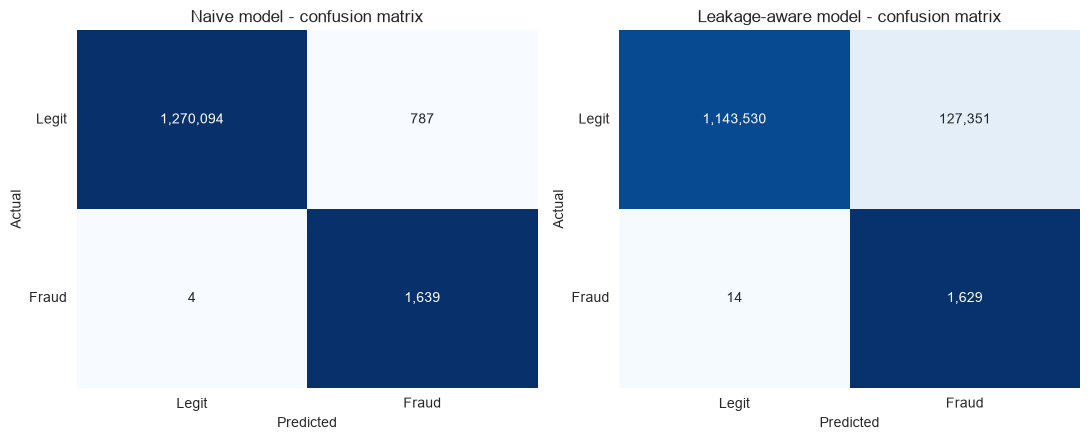

In [9]:
# Colors show the share of each actual class (per row), numbers show the counts.
# This way the small fraud row is also visible.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ['Legit', 'Fraud']

for ax, cm, title in [(axes[0], naive_cm, 'Naive model'),
                      (axes[1], safe_cm, 'Leakage-aware model')]:
    cm_share = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_share, annot=cm, fmt=',d', cmap='Blues', vmin=0, vmax=1, cbar=False,
                ax=ax, xticklabels=labels, yticklabels=labels)
    ax.set_title(f'{title} - confusion matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('../reports/figures/leakage_confusion_matrices.png', dpi=120)
plt.show()

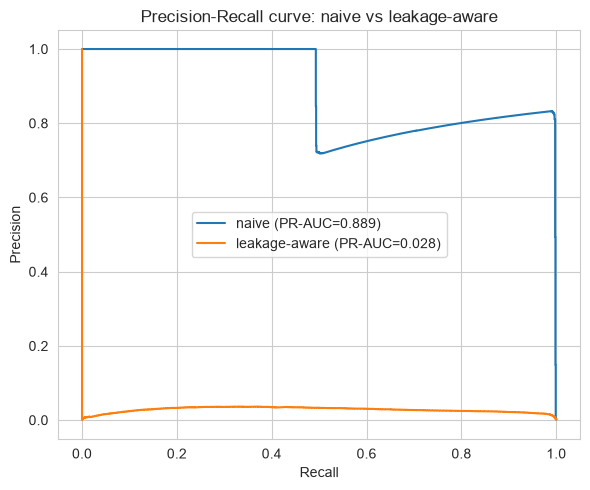

In [10]:
precision_naive, recall_naive, _ = precision_recall_curve(y_test, naive_proba)
precision_safe, recall_safe, _ = precision_recall_curve(y_test, safe_proba)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_naive, precision_naive, label=f"naive (PR-AUC={naive_metrics['pr_auc']:.3f})")
ax.plot(recall_safe, precision_safe, label=f"leakage-aware (PR-AUC={safe_metrics['pr_auc']:.3f})")
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curve: naive vs leakage-aware')
ax.legend(loc='center')
plt.tight_layout()
plt.savefig('../reports/figures/leakage_pr_curve.png', dpi=120)
plt.show()

## Interpretation

**Recall** is almost the same for both models (99.8% vs 99.1%). Only 14 frauds are missed instead of 4. But with `class_weight='balanced'` a high recall is easy to get, so we should not read too much into it.

**Precision** is where they differ: 67.6% for the naive model vs 1.3% for the leakage-aware one. Without the post-transaction columns, the model flags 127,351 normal transactions as fraud (about 10% of the 1,270,881 in the test set). A fraud team could not work with that many false alerts.

**PR-AUC** drops from 0.889 to 0.028, about 32 times lower. So the naive model's score comes almost fully from the columns measured after the transaction (`newbalanceOrig`, `newbalanceDest` and the flags built from them).

**Careful:** 0.028 is not the real limit of the safe features. This is a simple linear model with only 4 features. The amount-to-balance ratio works like a threshold (fraud is close to 1.0), and Logistic Regression is not good at this. We will test better models later.

## Extra Check: oldbalanceDest

The naive set also contains `oldbalanceDest`, so we don't know yet how much it adds on its own. It is known before the transaction, but it could carry the same artifact: for `CASH_OUT` and `TRANSFER`, the destination balance is 0 before and after for 49.6% of fraud vs 0.06% of non-fraud.

So we add only `oldbalanceDest` to the leakage-aware set and test it.

In [11]:
intermediate_numeric = safe_numeric + ['oldbalanceDest_log']
intermediate_categorical = ['type']

interm_model, interm_metrics, interm_cm, interm_proba = build_and_evaluate(
    intermediate_numeric, intermediate_categorical, 'leakage-aware + oldbalanceDest'
)

In [12]:
comparison_all = pd.DataFrame([naive_metrics, interm_metrics, safe_metrics]).set_index('label')
comparison_all.round(4)

,precision,recall,f1,roc_auc,pr_auc
label,,,,,
naive (with new balances),0.6756,0.9976,0.8056,0.9994,0.8892
leakage-aware + oldbalanceDest,0.0126,0.9890,0.0249,0.9776,0.0384
leakage-aware (pre-transaction only),0.0126,0.9915,0.0249,0.9744,0.0278


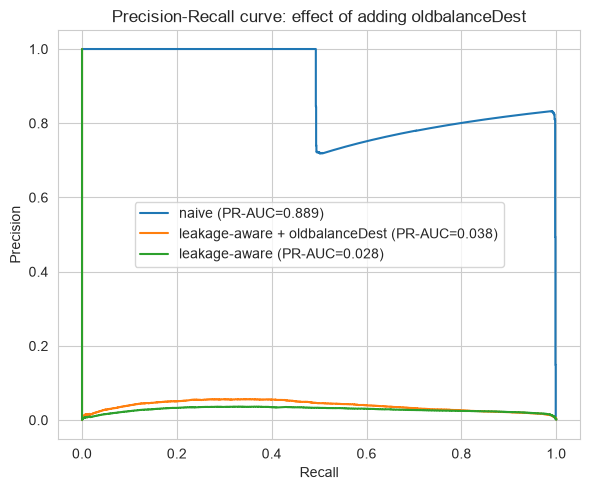

In [13]:
precision_interm, recall_interm, _ = precision_recall_curve(y_test, interm_proba)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_naive, precision_naive, label=f"naive (PR-AUC={naive_metrics['pr_auc']:.3f})")
ax.plot(recall_interm, precision_interm, label=f"leakage-aware + oldbalanceDest (PR-AUC={interm_metrics['pr_auc']:.3f})")
ax.plot(recall_safe, precision_safe, label=f"leakage-aware (PR-AUC={safe_metrics['pr_auc']:.3f})")
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curve: effect of adding oldbalanceDest')
ax.legend(loc='center')
plt.tight_layout()
plt.savefig('../reports/figures/leakage_oldbalancedest_pr_curve.png', dpi=120)
plt.show()

Adding `oldbalanceDest` gives a small gain: PR-AUC goes from 0.028 to 0.038. Precision does not change (1.3%) and recall is a bit lower (98.9% vs 99.1%, 1,625 vs 1,629 frauds caught). The curve stays far below the naive one.

Compared with the 32 times drop seen with the post-transaction columns, this is nothing. So `oldbalanceDest` looks like a normal feature with a small signal, not a leak.

## Decision

**Excluded:** `newbalanceOrig`, `newbalanceDest` and the flags built from them (`balance_orig_consistent`, `balance_dest_consistent`, `zero_dest_balance`). The flags cannot be computed without these columns. Removing them drops PR-AUC about 32 times (0.889 to 0.028) while recall barely changes, so they carried almost all the naive model's performance.

**Kept:** `oldbalanceDest`. Adding it back gives only a small gain (PR-AUC 0.028 to 0.038), nothing like the 32 times drop.

**Final feature set for `05_feature_engineering.ipynb`:** `type`, `amount`, `oldbalanceOrg`, `oldbalanceDest` and `amount_to_balance_ratio`, plus new features built from them. `isFlaggedFraud` stays excluded (decided earlier: it catches only 0.19% of fraud).